# 02 — Latent injury profiles and approaching-event changes

**Question.** Do injury groups occupy different regions of the frozen latent maps, and is separation persistent or changing?

In [1]:
from pathlib import Path
import sys
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'config/injury_reduction.yaml').exists())
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
from src.injury_analysis.reduction import CFG,OUT,CACHE,inputs,read_table
from src.injury_analysis import reduction_plots as plots
from src.injury_analysis.common import conclusion
pd.set_option('display.max_columns',16)


## Matched, out-of-training comparisons
Reuse the **exact original matched case/control identities and outing keys**. The primary curves use pairs whose entire observed windows and injury anchors fall in 2022–2025, after PCA fitting. All-year curves, including partial 2026, are saved separately as description. These are already examined periods, not fresh confirmation.

A plotted score requires all eight source measurements for its block. For each component/category, balanced curves keep both members of the **same pairs at all points**. Calendar time uses 31–60, 15–30, 8–14 and 1–7 days; appearance time uses the final five outings in the existing 60-day alignment. Scores are expressed in training-PC standard deviations. No smoothing, future baselines or reindexing invent observations. Source dates remain recorded injury/IL proxies, not biological onset.

In [2]:
from src.injury_analysis.reduction_trajectories import run_latent_trajectories
a,events,spec,matches=inputs()
trajectories=run_latent_trajectories(events,matches)
display(read_table('latent_alignment_coverage'))
display(trajectories.query("cohort=='Heldout 2022–2025' and kind=='difference' and point==0")[[
 'feature','mode','category','events','pitchers']])

Latent trajectories: Heldout 2022–2025, 443 original pairs


Latent trajectories: All years descriptive, 1225 original pairs


,analysis_group,kind,events,appearances,profile_complete_fraction,departure_complete_fraction
0,Elbow / UCL,Control,225,2640,0.999242,0.984091
1,Elbow / UCL,Injury,225,2518,1.000000,0.986894
2,Forearm,Control,84,999,0.998999,0.988989
3,Forearm,Injury,84,1014,1.000000,0.980276
4,Hand / wrist,Control,68,840,1.000000,0.989286
5,Hand / wrist,Injury,68,712,1.000000,0.992978
6,Lower body,Control,280,3255,1.000000,0.986175
7,Lower body,Injury,280,3230,0.998762,0.986068
8,Other arm,Control,85,1031,0.998060,0.982541
9,Other arm,Injury,85,1008,0.999008,0.979167


,feature,mode,category,events,pitchers
8,profile_PC1,calendar,Elbow / UCL,33,33
20,profile_PC1,calendar,Forearm,22,22
32,profile_PC1,calendar,Hand / wrist,13,12
44,profile_PC1,calendar,Lower body,47,44
56,profile_PC1,calendar,Other arm,14,14
...,...,...,...,...,...
1069,departure_PC3,appearance,Hand / wrist,19,17
1084,departure_PC3,appearance,Lower body,69,61
1099,departure_PC3,appearance,Other arm,27,26
1114,departure_PC3,appearance,Shoulder,68,68


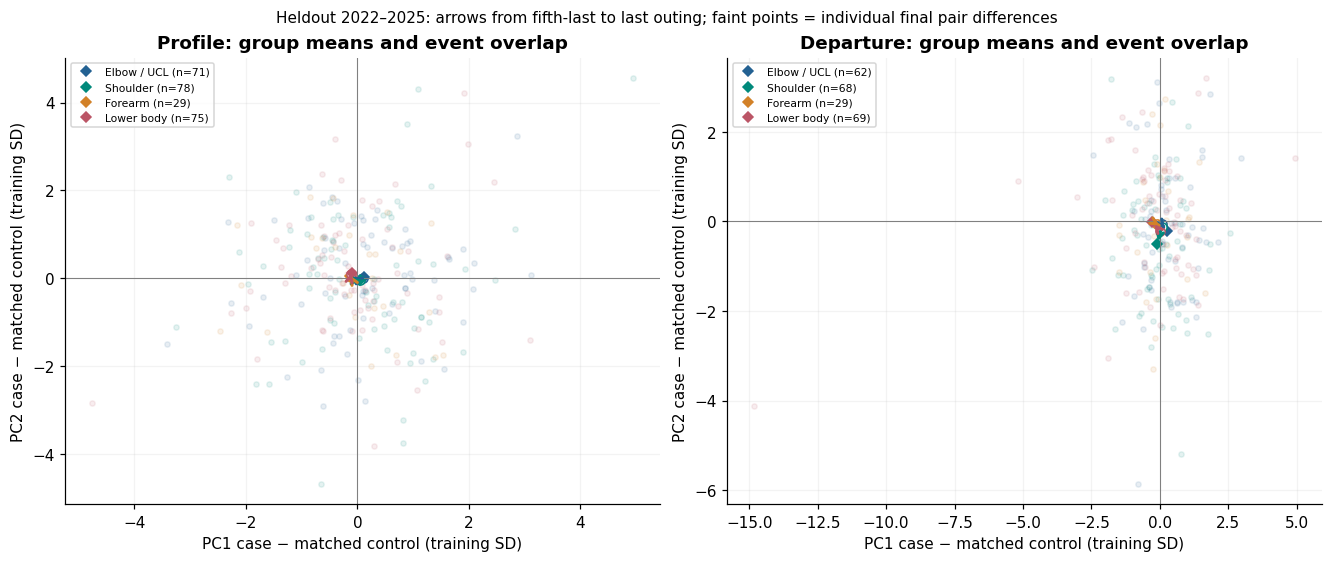

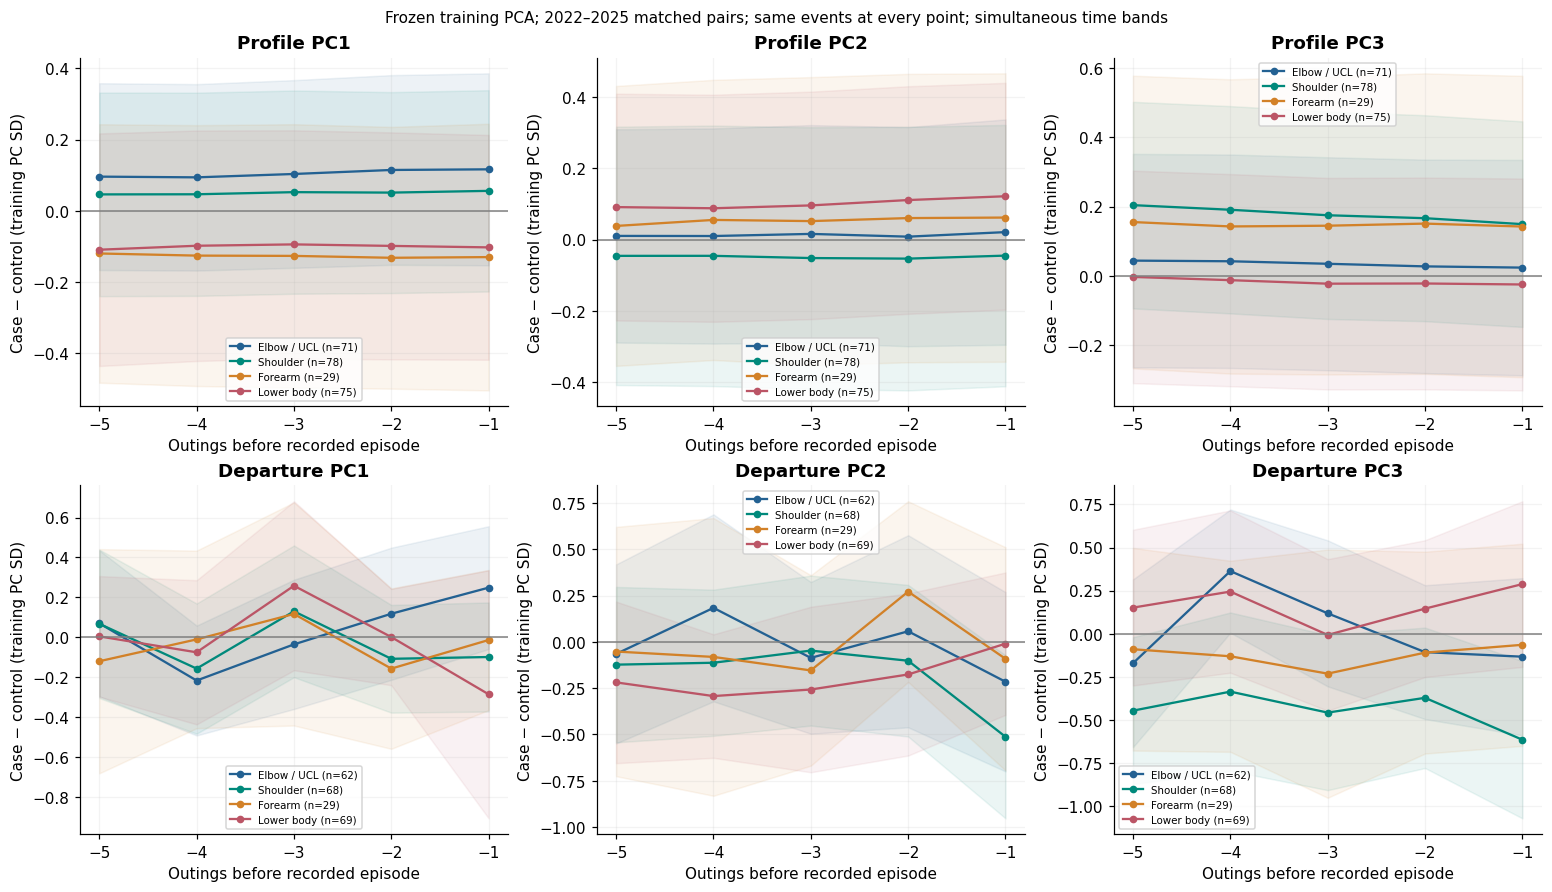

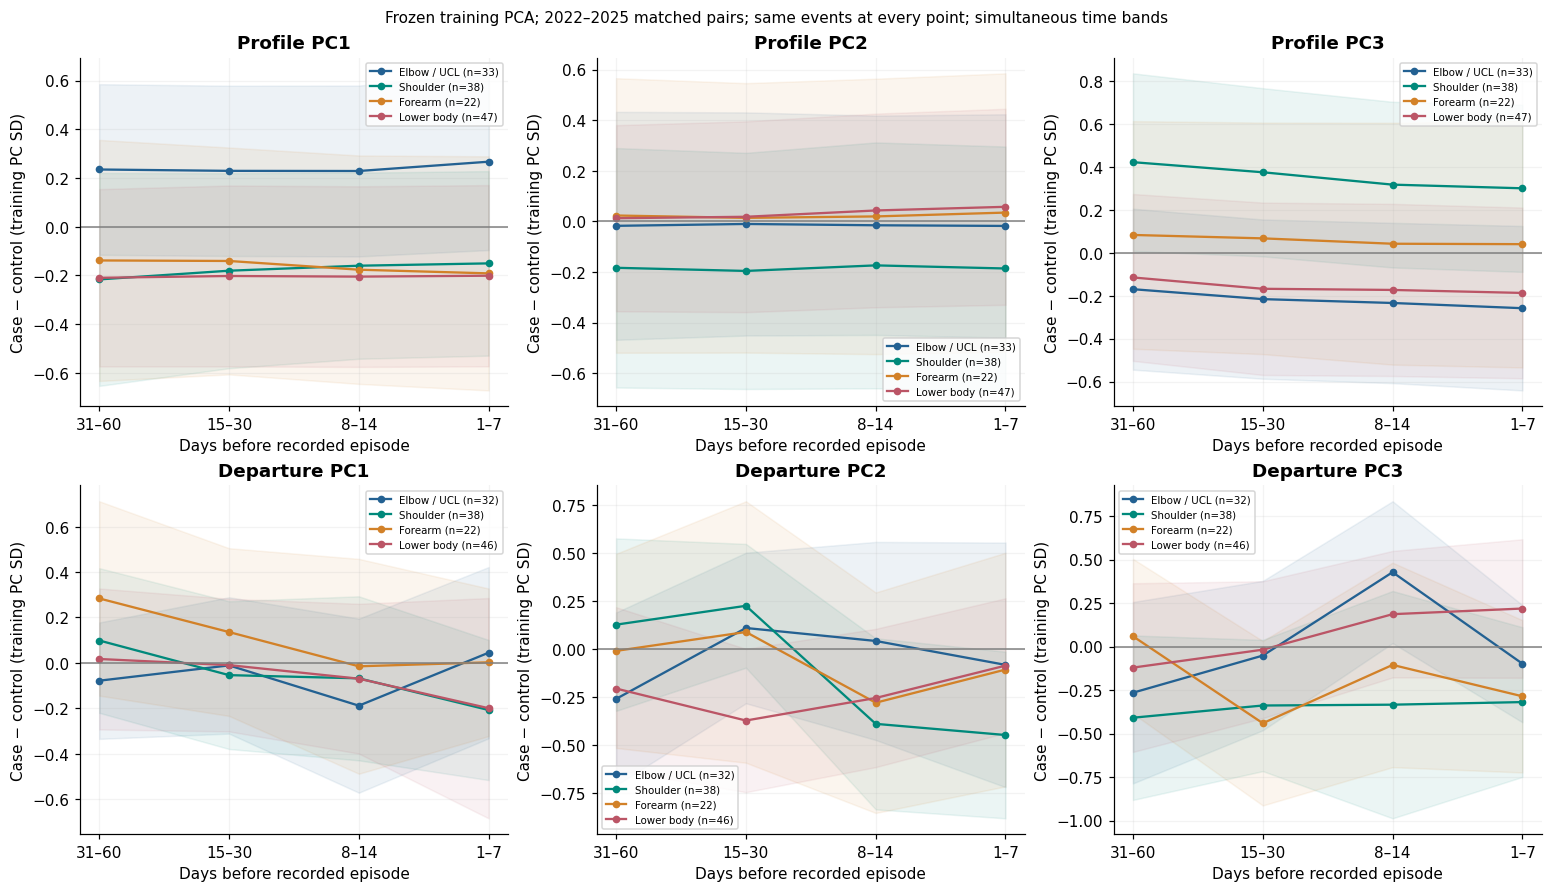

In [3]:
plots.latent_map_figure();plt.show()
plots.latent_trajectory_figure('appearance');plt.show()
plots.latent_trajectory_figure('calendar');plt.show()

## Persistent offset versus evolving separation
Each event contributes one paired summary. Average separation describes the offset across the window. Final-step change is (case last minus case previous two) minus (control last minus control previous two). These answer different questions. Profile baselines are smooth by construction; a stable profile offset is not proof of susceptibility. Departure PCs may mix changing velocity with release, spin and extension, so interpret them with notebook 01's loadings.

Uncertainty resamples whole case pitchers, retaining their episodes. Time bands are simultaneous **within a component/category**; they do not adjust across every component or injury comparison. The scatter shows event overlap, not clustering accuracy. A person's participation as a control elsewhere can retain some cross-pair dependence.

In [4]:
shapes=read_table('latent_shape_contrasts')
display(shapes.query("cohort=='Heldout 2022–2025' and mode=='appearance' and metric in ['average_separation','final_step_vs_previous_two']")[[
 'feature','category','metric','mean','low','high','events']])
display(read_table('latent_sensitivity').query("feature in ['profile_PC1','departure_PC2']"))
s=shapes.query("cohort=='Heldout 2022–2025' and mode=='appearance' and feature=='departure_PC2' and metric=='final_step_vs_previous_two'").set_index('category')
conclusion(f"The velocity/release/spin/extension departure PC2 changes by {s.loc['Shoulder','mean']:.3f} training-PC SD in the shoulder final-step contrast (interval {s.loc['Shoulder','low']:.3f} to {s.loc['Shoulder','high']:.3f}; {int(s.loc['Shoulder','events'])} pairs), versus {s.loc['Elbow / UCL','mean']:.3f} for elbow/UCL ({s.loc['Elbow / UCL','low']:.3f} to {s.loc['Elbow / UCL','high']:.3f}). All axes, uncertainty and support are retained; these group trajectories do not establish individual early-warning thresholds.")

,feature,category,metric,mean,low,high,events
14,profile_PC1,Elbow / UCL,average_separation,0.105047,-0.166353,0.347594,71
15,profile_PC1,Elbow / UCL,final_step_vs_previous_two,0.007441,-0.009745,0.031052,71
19,profile_PC1,Forearm,average_separation,-0.126822,-0.458275,0.260745,29
20,profile_PC1,Forearm,final_step_vs_previous_two,-0.000720,-0.015574,0.015419,29
24,profile_PC1,Hand / wrist,average_separation,0.160794,-0.319675,0.576826,20
...,...,...,...,...,...,...,...
280,departure_PC3,Other arm,final_step_vs_previous_two,0.084883,-0.372397,0.611994,27
284,departure_PC3,Shoulder,average_separation,-0.444694,-0.660354,-0.230141,68
285,departure_PC3,Shoulder,final_step_vs_previous_two,-0.200010,-0.546553,0.144626,68
289,departure_PC3,Trunk / neck,average_separation,-0.165324,-0.477353,0.110785,48


,condition,feature,category,mean,low,high,events,pitchers
0,Primary,profile_PC1,Elbow / UCL,0.031436,-0.181735,0.232598,92,88
1,Primary,profile_PC1,Forearm,-0.081046,-0.409634,0.199514,37,37
2,Primary,profile_PC1,Hand / wrist,0.126550,-0.308897,0.549363,22,20
3,Primary,profile_PC1,Lower body,-0.113429,-0.390631,0.144796,93,80
4,Primary,profile_PC1,Other arm,0.103467,-0.212785,0.473143,37,36
...,...,...,...,...,...,...,...,...
240,Exclude final seven days,departure_PC2,Hand / wrist,0.127813,-0.531302,0.608594,18,17
241,Exclude final seven days,departure_PC2,Lower body,-0.242040,-0.550077,0.016140,77,67
242,Exclude final seven days,departure_PC2,Other arm,0.013487,-0.482012,0.485743,32,31
243,Exclude final seven days,departure_PC2,Shoulder,-0.172230,-0.419700,0.093909,83,80


**Computed conclusion.** The velocity/release/spin/extension departure PC2 changes by -0.438 training-PC SD in the shoulder final-step contrast (interval -0.831 to -0.112; 68 pairs), versus -0.201 for elbow/UCL (-0.621 to 0.224). All axes, uncertainty and support are retained; these group trajectories do not establish individual early-warning thresholds.